In [23]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


# **Реализовать преобразование Хаара (3 ступени сжатия).**

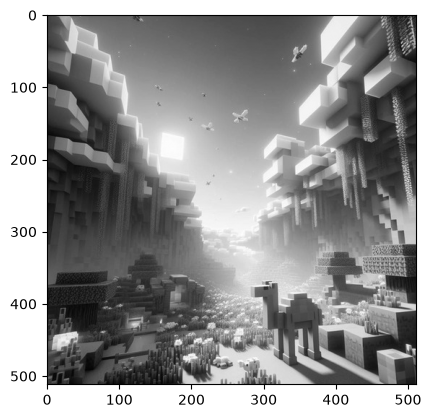

In [24]:
image = cv2.imread('minecraft.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

In [25]:
image_gray = image_gray.astype(np.float32)
def haar(image):
    h, w = image.shape
    
    # Четные столбцы: 0, 2, 4... Нечетные: 1, 3, 5...
    a = image[:, 0::2]  # левые пиксели
    b = image[:, 1::2]  # правые пиксели
    
    # Горизонтальный шаг
    avg_h = (a + b) / 2
    diff_h = (a - b) / 2
    temp = np.hstack((avg_h, diff_h)) # склеиваем левую и правую половины
    
    # Вертикальный шаг
    a_v = temp[0::2, :] # верхние
    b_v = temp[1::2, :] # нижние
    
    avg_v = (a_v + b_v) / 2
    diff_v = (a_v - b_v) / 2
    
    res = np.vstack((avg_v, diff_v)) # склеиваем верхнюю и нижнюю половины
    
    return res

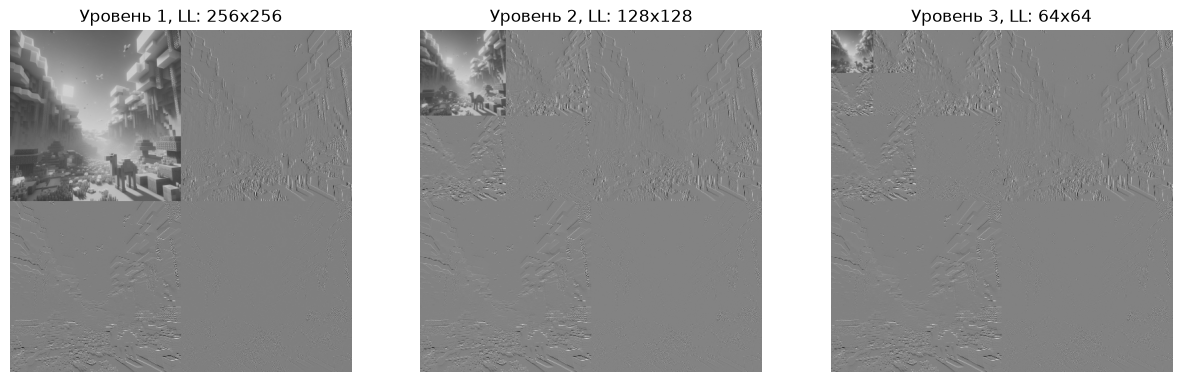

In [26]:
res = image_gray.copy()
n = 512
compressed = []

plt.figure(figsize=(15, 5))
for l in range(1, 4):
    res[:n, :n] = haar(res[:n, :n])
    n //= 2
    compressed.append(res[:n, :n].copy())

    res_show = 128 + 3 * res
    res_show[:n, :n] = res[:n, :n]
    plt.subplot(1, 3, l)
    plt.imshow(res_show, cmap='gray')
    plt.title(f'Уровень {l}, LL: {n}x{n}')
    plt.axis('off')

Ступень 1:  размер (256, 256), меньше в 4 раз(-а)
Ступень 2:  размер (128, 128), меньше в 16 раз(-а)
Ступень 3:  размер (64, 64), меньше в 64 раз(-а)


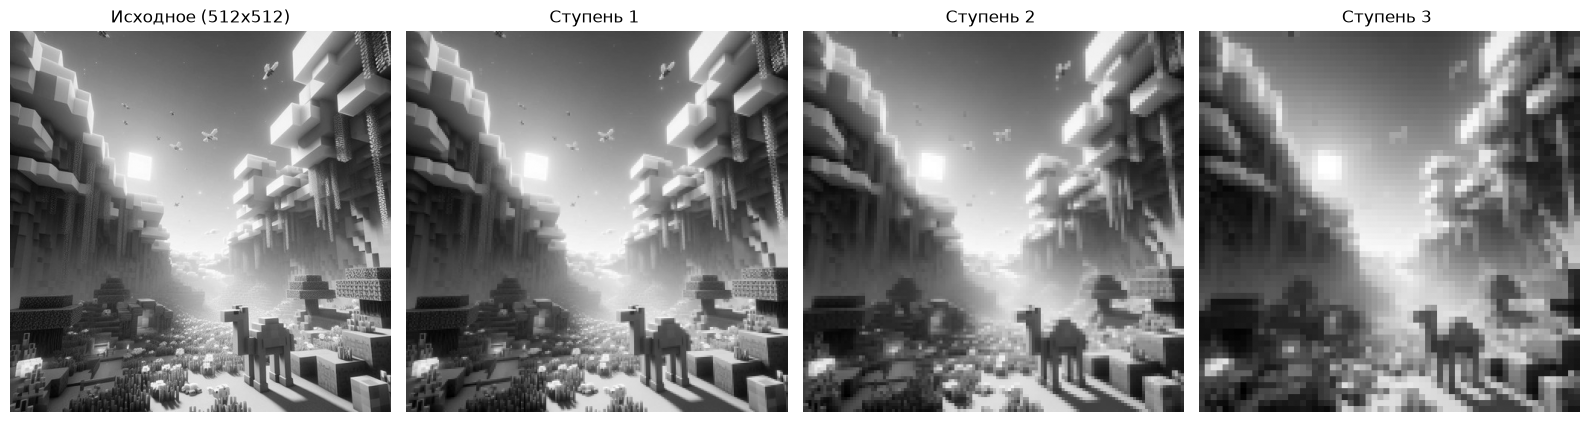

In [27]:
plt.figure(figsize=(16, 5))


plt.subplot(1, 4, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное (512x512)')
plt.axis('off')

for i in range(3):
    # Растягиваем маленький сжатый уголок до размера оригинала (512x512)
    
    image_decomp = cv2.resize(compressed[i], (512, 512), interpolation=cv2.INTER_NEAREST)
    
    plt.subplot(1, 4, i + 2)
    plt.imshow(image_decomp, cmap='gray')
    plt.title(f'Ступень {i + 1} ')
    plt.axis('off')
    
    # Считаем, во сколько раз меньше данных
    compression_ratio = image_gray.size // compressed[i].size
    print(f'Ступень {i + 1}:  размер {compressed[i].shape}, меньше в {compression_ratio} раз(-а)')

plt.tight_layout()
plt.show()